## Step 1: Install and imports

In [1]:
!pip install -U ultralytics --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.7 MB/s eta 0:00:00


## Step 2: Shared helpers

In [2]:
"""Shared helpers used by notebooks 02, 03 and 04.
"""
import os
import time
import random
import shutil

import numpy as np
import pandas as pd
import cv2

IMG_SIZE = 224
MODALITY_PIXEL = {0: 0, 1: 85, 2: 170, 3: 255}   # CTA, MRA, MRI T1post, MRI T2
MODALITY_NAMES = {0: "CTA", 1: "MRA", 2: "MRI T1post", 3: "MRI T2"}

SPLIT_NAMES = ["70_15_15", "80_10_10", "85_7dot5_7dot5"]
MAIN_SPLIT = "70_15_15"       # model comparison split (largest test set); other splits are ablations in notebook 03

# Colour jitter is disabled on purpose: the images are grayscale-derived and the
# third channel is a constant that encodes the modality, so hue/saturation/value
# changes would only corrupt that signal.
YOLO_COMMON = dict(epochs=50, imgsz=IMG_SIZE, batch=32, patience=15, seed=42,
                   hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, plots=False, exist_ok=True)


# --------------------------------------------------------------------------
# Locating files produced by notebook 01 / 02 (Kaggle nests outputs unpredictably)
# --------------------------------------------------------------------------
def find_file(name, base="/kaggle/input", max_depth=5,
              skip=("rsna-intracranial-aneurysm-detection",
                    "rsna-2025-intracranial-aneurysm-png-224x224")):
    """Walk `base` (bounded depth, skipping the huge raw datasets) and return the shortest match."""
    hits = []
    for root, dirs, files in os.walk(base):
        depth = root[len(base):].count(os.sep)
        dirs[:] = [d for d in dirs if d not in skip] if depth < max_depth else []
        if name in files:
            hits.append(os.path.join(root, name))
    return sorted(hits, key=len)[0] if hits else None


def find_data_root():
    path = find_file("final_df_v2.csv")
    assert path is not None, ("final_df_v2.csv not found. Add the output of notebook 01 "
                              "(Add Input -> Your Work -> Notebook output).")
    return os.path.dirname(path)


def load_split(split_name, data_root):
    """Read split_<name>.csv and attach absolute image paths (image_path in the CSV is relative)."""
    df = pd.read_csv(os.path.join(data_root, f"split_{split_name}.csv"))
    df["abs_path"] = data_root + "/" + df["image_path"]
    return df


# --------------------------------------------------------------------------
# Image construction
# --------------------------------------------------------------------------
def make_modality_image(gray, modality_code):
    """Stack [gray, gray, constant-modality-channel]."""
    h, w = gray.shape
    mod = np.full((h, w), MODALITY_PIXEL.get(int(modality_code), 128), dtype=np.uint8)
    return np.stack([gray, gray, mod], axis=-1)


def make_plain_image(gray):
    return np.stack([gray, gray, gray], axis=-1)


def transform_image_and_boxes(gray, boxes, kind, angle=0.0):
    """Apply orig / flip / rot to a grayscale image and its boxes.

    boxes: list of (xc, yc, w, h) in normalised coordinates.
    Returns (image, boxes). Boxes whose centre leaves the image after rotation are dropped.
    """
    if kind == "orig":
        return gray, list(boxes)
    if kind == "flip":
        return cv2.flip(gray, 1), [(1.0 - x, y, w, h) for x, y, w, h in boxes]
    if kind == "rot":
        h_img, w_img = gray.shape
        M = cv2.getRotationMatrix2D((w_img / 2, h_img / 2), angle, 1.0)
        rot = cv2.warpAffine(gray, M, (w_img, h_img), borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        out = []
        for x, y, w, h in boxes:
            px, py = x * w_img, y * h_img
            nx = (M[0, 0] * px + M[0, 1] * py + M[0, 2]) / w_img
            ny = (M[1, 0] * px + M[1, 1] * py + M[1, 2]) / h_img
            if 0.0 <= nx <= 1.0 and 0.0 <= ny <= 1.0:
                out.append((nx, ny, w, h))
        return rot, out
    raise ValueError(kind)


def image_table(split_df):
    """Collapse the box-level table to one row per image with its list of boxes."""
    rows = []
    for path, g in split_df.groupby("abs_path", sort=False):
        first = g.iloc[0]
        boxes = [(r.x_center, r.y_center, r.box_w, r.box_h) for r in g.itertuples()
                 if pd.notna(r.x_center)]
        rows.append(dict(abs_path=path, SeriesInstanceUID=first["SeriesInstanceUID"],
                         Modality=first["Modality"], modality_code=int(first["modality_code"]),
                         label=int(len(boxes) > 0), boxes=boxes, split=first["split"]))
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------
# YOLO dataset export
# --------------------------------------------------------------------------
def _write_label(path, boxes):
    with open(path, "w") as f:
        f.write("\n".join(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for x, y, w, h in boxes))


def _link_or_copy(src, dst):
    try:
        os.link(src, dst)          # hard link: no extra disk space for oversampled duplicates
    except OSError:
        shutil.copy(src, dst)


def build_yolo_dataset(split_df, root, modality_aware=True, balance=True,
                       rot_deg=15, use_flip=True, seed=42):
    """Export one split to YOLO format.

    train: orig (+ flip) (+ rotation by +-rot_deg) variants of every image, all boxes of an
           image kept together; optional modality oversampling with hard links.
    val/test: original images only.
    Returns (yaml_path, stats_dict).
    """
    rng = random.Random(seed)
    if os.path.exists(root):
        shutil.rmtree(root)
    img_tab = image_table(split_df)

    def render(gray, code):
        return make_modality_image(gray, code) if modality_aware else make_plain_image(gray)

    stats, file_modality = {}, {}
    for part in ["train", "val", "test"]:
        os.makedirs(f"{root}/images/{part}", exist_ok=True)
        os.makedirs(f"{root}/labels/{part}", exist_ok=True)
        sub = img_tab[img_tab["split"] == part].reset_index(drop=True)
        n_files = 0
        for k, r in sub.iterrows():
            gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
            if gray is None:
                continue
            kinds = ["orig"]
            if part == "train":
                if use_flip:
                    kinds.append("flip")
                if rot_deg and rot_deg > 0:
                    kinds.append("rot")
            angle = rng.choice([-rot_deg, rot_deg]) if (part == "train" and rot_deg) else 0
            for kind in kinds:
                img_t, boxes_t = transform_image_and_boxes(gray, r["boxes"], kind, angle)
                if r["label"] == 1 and len(boxes_t) == 0:
                    continue                       # rotation pushed every box out of the frame
                base = f"{r['SeriesInstanceUID']}_{k}_{kind}"
                cv2.imwrite(f"{root}/images/{part}/{base}.png", render(img_t, r["modality_code"]))
                _write_label(f"{root}/labels/{part}/{base}.txt", boxes_t)
                file_modality[(part, base)] = r["Modality"]
                n_files += 1
        stats[part] = dict(images=n_files,
                           positive_images=int(sub["label"].sum()) if part != "train" else None,
                           boxes=int(sub["boxes"].apply(len).sum()) if part != "train" else None,
                           series=int(sub["SeriesInstanceUID"].nunique()))

    if balance:
        by_mod = {}
        for (part, base), mod in file_modality.items():
            if part == "train":
                by_mod.setdefault(mod, []).append(base)
        target = max(len(v) for v in by_mod.values())
        for mod, bases in by_mod.items():
            extra = rng.choices(bases, k=target - len(bases)) if len(bases) < target else []
            for i, base in enumerate(extra):
                _link_or_copy(f"{root}/images/train/{base}.png", f"{root}/images/train/{base}_dup{i}.png")
                _link_or_copy(f"{root}/labels/train/{base}.txt", f"{root}/labels/train/{base}_dup{i}.txt")
        stats["train_balanced_per_modality"] = target

    stats["train"]["images"] = len(os.listdir(f"{root}/images/train"))
    stats["train"]["positive_images"] = int(sum(
        os.path.getsize(f"{root}/labels/train/{f}") > 0 for f in os.listdir(f"{root}/labels/train")))
    pd.DataFrame([dict(part=p, base=b, Modality=m) for (p, b), m in file_modality.items()]
                 ).to_csv(f"{root}/file_modality.csv", index=False)
    yaml_path = f"{root}/data.yaml"
    with open(yaml_path, "w") as f:
        f.write(f"path: {root}\ntrain: images/train\nval: images/val\ntest: images/test\n\n"
                f"names:\n  0: aneurysm\n")
    return yaml_path, stats


def make_modality_subsets(root, out_root):
    """Hard-link the test images of each modality into their own folder with a yaml (for per-modality eval)."""
    fm = pd.read_csv(f"{root}/file_modality.csv")
    fm = fm[fm["part"] == "test"]
    yamls = {}
    for mod, g in fm.groupby("Modality"):
        tag = mod.replace(" ", "_")
        for sub in ["images/test", "labels/test", "images/val", "labels/val"]:
            os.makedirs(f"{out_root}/{tag}/{sub}", exist_ok=True)
        for base in g["base"]:
            for d, ext in [("images", "png"), ("labels", "txt")]:
                for part in ["test", "val"]:
                    dst = f"{out_root}/{tag}/{d}/{part}/{base}.{ext}"
                    if not os.path.exists(dst):
                        _link_or_copy(f"{root}/{d}/test/{base}.{ext}", dst)
        y = f"{out_root}/{tag}/data.yaml"
        with open(y, "w") as f:
            f.write(f"path: {out_root}/{tag}\ntrain: images/test\nval: images/val\ntest: images/test\n\n"
                    f"names:\n  0: aneurysm\n")
        yamls[mod] = (y, len(g))
    return yamls


# --------------------------------------------------------------------------
# Result bookkeeping (lets a crashed notebook resume)
# --------------------------------------------------------------------------
def done_ids(csv_path, col="run_id"):
    return set(pd.read_csv(csv_path)[col]) if os.path.exists(csv_path) else set()


def append_row(csv_path, row):
    """Append one result row; columns are aligned even if the new row has extra/missing keys."""
    new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        new = pd.concat([pd.read_csv(csv_path), new], ignore_index=True)
    new.to_csv(csv_path, index=False)


def train_eval_yolo(weights, data_yaml, run_id, project, extra=None):
    """Train, then evaluate best.pt on val and test. Returns (metrics_row, best_pt_path)."""
    from ultralytics import YOLO
    params = dict(YOLO_COMMON)
    params.update(extra or {})
    imgsz = int(params["imgsz"])
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=data_yaml, project=project, name=run_id, **params)
    best_path = str(model.trainer.best)
    minutes = (time.time() - t0) / 60
    best = YOLO(best_path)
    out = {}
    for split in ["val", "test"]:
        r = best.val(data=data_yaml, split=split, imgsz=imgsz, project=project,
                     name=f"{run_id}_{split}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        out[split] = dict(map50=float(r.box.map50), map5095=float(r.box.map), precision=p, recall=rec,
                          f1=(2 * p * rec / (p + rec)) if (p + rec) > 0 else 0.0)
    row = dict(run_id=run_id, imgsz=imgsz, train_minutes=round(minutes, 1))
    for split in ["val", "test"]:
        for k, v in out[split].items():
            row[f"{split}_{k}"] = round(v, 4)
    return row, best_path


def conf_sweep(best_path, data_yaml, project, confs=(0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5), imgsz=IMG_SIZE):
    from ultralytics import YOLO
    model = YOLO(best_path)
    rows = []
    for c in confs:
        r = model.val(data=data_yaml, split="test", imgsz=imgsz, conf=c, project=project,
                      name=f"conf_{c}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        rows.append(dict(conf=c, map50=round(float(r.box.map50), 4), map5095=round(float(r.box.map), 4),
                         precision=round(p, 4), recall=round(rec, 4),
                         f1=round(2 * p * rec / (p + rec), 4) if (p + rec) > 0 else 0.0))
    return pd.DataFrame(rows)

## Step 3: Experiment configuration and resume

In [3]:
import json
import matplotlib.pyplot as plt

OUT = "/kaggle/working"
PROJECT = f"{OUT}/runs"
RESULTS_CSV = f"{OUT}/ablation_results.csv"
DATA_ROOT = find_data_root()
print("Data root:", DATA_ROOT)

INCLUDE_NO_ROTATION = False      # set True to add a 0-degree (flip only) run to the rotation table
BASE = MAIN_SPLIT                # comparison split of notebook 02 (70_15_15)
ROT_SPLIT = "85_7dot5_7dot5"     # split used for the rotation ablation

DATASETS = dict(
    mod_bal=dict(modality_aware=True, balance=True),
    mod_unbal=dict(modality_aware=True, balance=False),
    plain_unbal=dict(modality_aware=False, balance=False),
)
EXTRA_BY_RUN = {"M7_no_mosaic": dict(mosaic=0.0)}

# Reference detector = best validation mAP50 in notebook 02 (never chosen on test results)
det_csv = find_file(f"det_results_{BASE}.csv")
assert det_csv, f"det_results_{BASE}.csv not found. Add notebook 02's output as input."
det_tab = pd.read_csv(det_csv).drop_duplicates("run_id", keep="last").sort_values("val_map50", ascending=False)
ref_row = det_tab.iloc[0]
extra = dict(EXTRA_BY_RUN.get(ref_row["run_id"], {}))
extra["imgsz"] = int(ref_row["imgsz"])
REF = dict(run_id=ref_row["run_id"], weights=ref_row["weights"], extra=extra, data=DATASETS[ref_row["dataset"]])
print(det_tab[["run_id", "val_map50"]].round(4).to_string(index=False))
print("Reference detector for the ablations:", REF)

def rid(split, rot):
    return f"{split}__rot{rot}"

EXPERIMENTS = [
    dict(run_id=rid("80_10_10", 15),       split="80_10_10",       rot=15),
    dict(run_id=rid("85_7dot5_7dot5", 15), split="85_7dot5_7dot5", rot=15),
    dict(run_id=rid(ROT_SPLIT, 10),        split=ROT_SPLIT,        rot=10),
    dict(run_id=rid(ROT_SPLIT, 20),        split=ROT_SPLIT,        rot=20),
]
if INCLUDE_NO_ROTATION:
    EXPERIMENTS.append(dict(run_id=rid(ROT_SPLIT, 0), split=ROT_SPLIT, rot=0))

prev = find_file("ablation_results.csv")
if prev and not os.path.exists(RESULTS_CSV):
    shutil.copy(prev, RESULTS_CSV)
    print("Resumed. Finished runs:", sorted(done_ids(RESULTS_CSV)))

base_id = rid(BASE, 15)
if base_id not in done_ids(RESULTS_CSV):
    row = ref_row.to_dict()
    row.update(run_id=base_id, split=BASE, rot=15, reused_from="notebook 02 / " + REF["run_id"])
    append_row(RESULTS_CSV, row)
    print("Reused", REF["run_id"], "from notebook 02 as the", BASE, "+ 15 degree run")

Data root: /kaggle/input/notebooks/workplace123/1-data-pipeline
     run_id  val_map50
M4_imgsz448     0.6491
M2_modality     0.5947
 M5_yolo26s     0.5900
M1_baseline     0.5761
 M6_yolo26m     0.5632
M3_balanced     0.5432
Reference detector for the ablations: {'run_id': 'M4_imgsz448', 'weights': 'yolo26n.pt', 'extra': {'imgsz': 448}, 'data': {'modality_aware': True, 'balance': True}}
Reused M4_imgsz448 from notebook 02 as the 70_15_15 + 15 degree run


## Step 4: Train and evaluate

In [4]:
for exp in EXPERIMENTS:
    if exp["run_id"] in done_ids(RESULTS_CSV):
        print("skip (done):", exp["run_id"])
        continue
    print(f"\n=== {exp['run_id']} ===")
    split_df = load_split(exp["split"], DATA_ROOT)
    root = f"{OUT}/yolo_ablation"
    yaml_path, stats = build_yolo_dataset(split_df, root, rot_deg=exp["rot"], use_flip=True, **REF["data"])
    print(stats)
    row, best_path = train_eval_yolo(REF["weights"], yaml_path, exp["run_id"], PROJECT, REF["extra"])
    row.update(split=exp["split"], rot=exp["rot"], reused_from="",
               train_images=stats["train"]["images"], test_images=stats["test"]["images"],
               test_boxes=stats["test"]["boxes"], test_series=stats["test"]["series"])
    append_row(RESULTS_CSV, row)
    print({k: row[k] for k in ["run_id", "test_map50", "test_map5095", "test_precision", "test_recall", "train_minutes"]})
    shutil.rmtree(root, ignore_errors=True)
    shutil.rmtree(PROJECT, ignore_errors=True)
print("Finished:", sorted(done_ids(RESULTS_CSV)))


=== 80_10_10__rot15 ===
{'train': {'images': 19368, 'positive_images': 7634, 'boxes': None, 'series': 3218}, 'val': {'images': 439, 'positive_images': 209, 'boxes': 214, 'series': 402}, 'test': {'images': 457, 'positive_images': 225, 'boxes': 229, 'series': 403}, 'train_balanced_per_modality': 4842}
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.87G      1.635      2.317   0.006506          5        448: 100% ━━━━━━━━━━━━ 606/606 5.7it/s 1:46
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.8it/s 1.5s
                   all        439        214       0.51      0.453      0.474      0.265

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.87G      1.633      2.266   0.006485          4        448: 100% ━━━━━━━━━━━━ 606/606 6.1it/s 1:39
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.8it/s 1.4s
                   all        439        214      0.503      0.369      0.387      0.227

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      2.87G       1.62      2.262   0.006413         10        448: 100% ━━━━━━━━━━━━ 606/606 6.1it/s 1:40
                 Class     Images  Instances      Box(P     

## Step 5: Ablation tables and figures

=== Split-ratio ablation (M4_imgsz448, +-15 deg) ===
     split  test_map50  test_map5095  test_precision  test_recall  test_f1  test_images  test_boxes
  70/15/15      0.5656        0.3970          0.6184       0.5272   0.5692          674         332
  80/10/10      0.5941        0.4211          0.6515       0.5502   0.5966          457         229
85/7.5/7.5      0.6221        0.4694          0.6519       0.6168   0.6339          338         170

=== Rotation ablation (M4_imgsz448, 85_7dot5_7dot5) ===
rotation  test_map50  test_map5095  test_precision  test_recall  test_f1
+-10 deg      0.6282        0.4657          0.5919       0.6570   0.6228
+-15 deg      0.6221        0.4694          0.6519       0.6168   0.6339
+-20 deg      0.6453        0.4820          0.7124       0.5828   0.6411


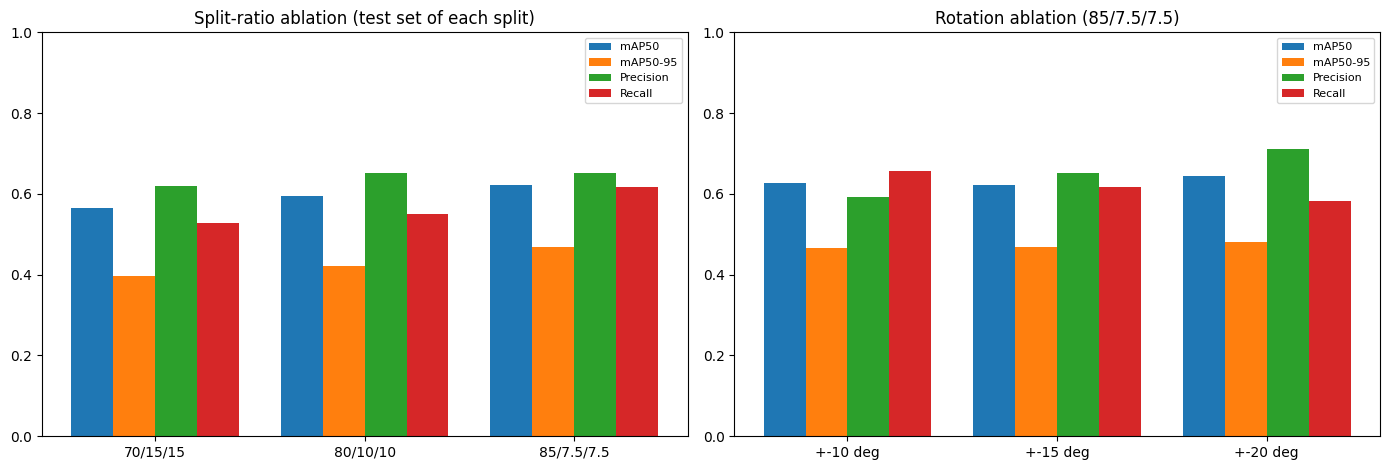

In [5]:
res = pd.read_csv(RESULTS_CSV).drop_duplicates("run_id", keep="last")
metric_cols = ["test_map50", "test_map5095", "test_precision", "test_recall", "test_f1"]

split_order = ["70_15_15", "80_10_10", "85_7dot5_7dot5"]
split_tab = res[res["rot"] == 15].set_index("split").reindex(split_order).reset_index()
split_tab["split"] = split_tab["split"].str.replace("dot5", ".5").str.replace("_", "/")
rot_tab = res[res["split"] == ROT_SPLIT].sort_values("rot").reset_index(drop=True)
rot_tab["rotation"] = rot_tab["rot"].apply(lambda r: "none" if r == 0 else f"+-{int(r)} deg")

print("=== Split-ratio ablation (" + REF["run_id"] + ", +-15 deg) ===")
print(split_tab[["split"] + metric_cols + ["test_images", "test_boxes"]].to_string(index=False))
print("\n=== Rotation ablation (" + REF["run_id"] + ", " + ROT_SPLIT + ") ===")
print(rot_tab[["rotation"] + metric_cols].to_string(index=False))
split_tab.to_csv(f"{OUT}/ablation_split_table.csv", index=False)
rot_tab.to_csv(f"{OUT}/ablation_rotation_table.csv", index=False)

def grouped_bars(ax, labels, table, title):
    x = np.arange(len(labels))
    w = 0.2
    for i, (col, lab) in enumerate([("test_map50", "mAP50"), ("test_map5095", "mAP50-95"),
                                    ("test_precision", "Precision"), ("test_recall", "Recall")]):
        vals = table[col].values
        ax.bar(x + (i - 1.5) * w, vals, w, label=lab)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
grouped_bars(axes[0], split_tab["split"].tolist(), split_tab, "Split-ratio ablation (test set of each split)")
grouped_bars(axes[1], rot_tab["rotation"].tolist(), rot_tab, "Rotation ablation (" + ROT_SPLIT.replace("dot5", ".5").replace("_", "/") + ")")
plt.tight_layout()
plt.savefig(f"{OUT}/fig_ablations.png", dpi=150)
plt.show()